In [201]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [202]:
df_raw = pd.read_csv('../data/raw/titanic_raw.csv')

In [203]:
df_raw.head()
df_raw.info()
df_raw.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [204]:
df_raw[df_raw.Age.isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
17,18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S
19,20,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C
26,27,0,3,"Emir, Mr. Farred Chehab",male,NaN,0,0,2631,7.2250,NaN,C
28,29,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,NaN,0,0,330959,7.8792,NaN,Q
...,...,...,...,...,...,...,...,...,...,...,...,...
859,860,0,3,"Razi, Mr. Raihed",male,NaN,0,0,2629,7.2292,NaN,C
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.5500,NaN,S
868,869,0,3,"van Melkebeke, Mr. Philemon",male,NaN,0,0,345777,9.5000,NaN,S
878,879,0,3,"Laleff, Mr. Kristo",male,NaN,0,0,349217,7.8958,NaN,S


In [205]:
df_raw[df_raw.duplicated()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [206]:
df_raw.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

In [207]:
df_raw.columns = df_raw.columns.str.lower().str.replace(' ', '_').str.strip()

In [208]:
df_raw['passengerid'].tail()
df_raw.drop(columns=['passengerid'], inplace=True)

In [209]:
df_raw

,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [210]:
df_raw['title'] = df_raw['name'].str.extract(r',\s*([^\.]+)\.', expand=False)

In [211]:
df_raw['title'] = df_raw['title'].apply(lambda x: 'Rare' if x not in ['Mr', 'Miss', 'Mrs', 'Master'] else x)

In [212]:
df_raw['title'].value_counts()

title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

In [213]:
df_raw.isna().sum()
df_raw['cabin'].nunique()
df_raw['cabin'].isna().sum()
df_raw['has_cabin'] = df_raw['cabin'].notna().astype(int)

In [214]:
df_raw['has_cabin'].value_counts()

has_cabin
0    687
1    204
Name: count, dtype: int64

In [215]:
df_raw['deck'] = df_raw['cabin'].str[0].fillna('unknown')

In [216]:
df_raw['deck'].value_counts()

deck
unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

In [217]:
df_raw['age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: age, dtype: float64

In [219]:
idades = df_raw['age'].dropna()

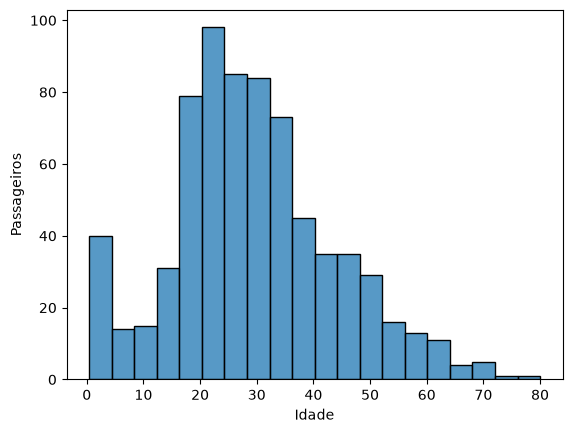

In [236]:
sns.histplot(x=idades, bins=20)
plt.xlabel('Idade')
plt.ylabel('Passageiros')
plt.show()

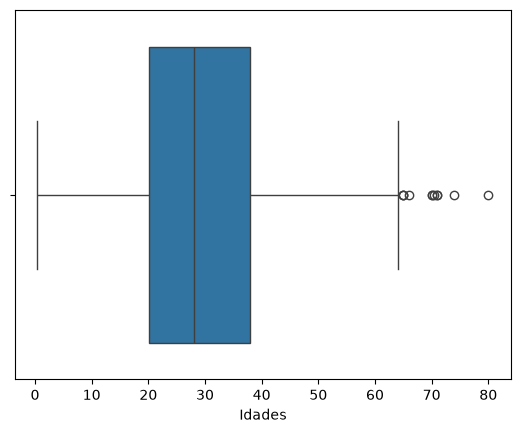

In [239]:
sns.boxplot(x=idades)
plt.xlabel('Idades')
plt.show()

In [244]:
df_raw[df_raw['age'] < 10].value_counts()

survived  pclass  name                             sex     age   sibsp  parch  ticket   fare      cabin    embarked  title   has_cabin  deck
1         3       Sandstrom, Miss. Marguerite Rut  female  4.00  1      1      PP 9549  16.7000   G6       S         Miss    1          G       1
          2       Becker, Master. Richard F        male    1.00  2      1      230136   39.0000   F4       S         Master  1          F       1
                  Navratil, Master. Michel M       male    3.00  1      1      230080   26.0000   F2       S         Master  1          F       1
0         3       Strom, Miss. Telma Matilda       female  2.00  0      1      347054   10.4625   G6       S         Miss    1          G       1
          1       Allison, Miss. Helen Loraine     female  2.00  1      2      113781   151.5500  C22 C26  S         Miss    1          C       1
1         1       Allison, Master. Hudson Trevor   male    0.92  1      2      113781   151.5500  C22 C26  S         Master  1   

In [264]:
medians = df_raw.groupby('title')['age'].median()


idade_sugerida = df_raw['title'].map(medians)


df_raw['age_estimate'] = idade_sugerida

In [266]:
df_raw.isna().sum()

survived          0
pclass            0
name              0
sex               0
age             177
sibsp             0
parch             0
ticket            0
fare              0
cabin           687
embarked          2
title             0
has_cabin         0
deck              0
age_estimate      0
dtype: int64